# 06 · Experimento controlado: ResNet18 con y sin aumentos de datos

> **Prototipo académico; no apto para diagnóstico ni decisiones clínicas.**

**Qué se cambia (una sola decisión):** los aumentos de entrenamiento.
- *con_aumentos*: volteo horizontal y rotación de ±10° (la configuración del notebook 05).
- *sin_aumentos*: ninguna transformación aleatoria.

**Qué se deja fijo:** ResNet18 preentrenada, lr 1e-4, 20 épocas, batch 16, Adam, la partición
de la semilla 42, el mismo preprocesamiento y la selección de la época por AUC de validación.

**Por qué este experimento:** en el notebook 05, ResNet18 llegó a AUC de entrenamiento 1,0
mientras el de validación bajaba (sobreajuste). Los aumentos son la decisión que tomamos
para frenar eso, y este experimento mide si de verdad ayudan.

**Repeticiones:** cada condición se entrena con 3 semillas de entrenamiento (42, 7 y 123). La
partición NO cambia: siempre es la de la semilla 42. Así se ve cuánto varía el AUC solo por
el azar del entrenamiento, y la diferencia entre condiciones se compara con esa variación.

**Regla de decisión (fijada antes de ejecutar):** se pasa a *sin_aumentos* solo si su AUC
medio de validación supera al de *con_aumentos* en al menos 0,02. Si no, se mantiene
*con_aumentos*, que es la configuración ya documentada. El modelo final es el de la semilla 42
de la condición elegida.

Solo se usan train y validación. La prueba no se carga. Tarda unos 5 minutos en una T4.

In [1]:
# Montar Drive y fijar rutas (las mismas en todos los notebooks)
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE    = "/content/drive/MyDrive/Aprendizaje final"
DATA    = f"{BASE}/Csv"
RES     = f"{BASE}/resultados"
SRC     = f"{BASE}/src"
PART    = f"{RES}/particiones"
PNG     = f"{BASE}/procesadas_224"     # recortes preprocesados (no van a Git)
MODELOS = f"{BASE}/modelos"            # checkpoints .pt (no van a Git)
for p in [DATA, RES, SRC, PART]:
    assert os.path.exists(p), f"No existe: {p}"
sys.path.insert(0, SRC)

Mounted at /content/drive


In [2]:
import json, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import modelo_utils as mu

SEMILLAS = [42, 7, 123]
CONDICIONES = {"con_aumentos": dict(flip=True, rotacion=10),
               "sin_aumentos": dict(flip=False, rotacion=0)}
EPOCAS, LR, BATCH = 20, 1e-4, 16
MARGEN = 0.02                    # regla de decisión, fijada antes de ejecutar

EXP = f"{RES}/experimento"
os.makedirs(EXP, exist_ok=True); os.makedirs(MODELOS, exist_ok=True)
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
GPU = torch.cuda.get_device_name(0) if dispositivo == "cuda" else "CPU"
print("Dispositivo:", GPU)

train = pd.read_csv(f"{PART}/train.csv")
val   = pd.read_csv(f"{PART}/val.csv")
assert len(set(train.patient_id) & set(val.patient_id)) == 0
print("train:", len(train), "| val:", len(val))

Dispositivo: Tesla T4
train: 146 | val: 37


In [3]:
filas, historiales = [], {}
for cond, aum in CONDICIONES.items():
    for sem in SEMILLAS:
        print(f"\n=== {cond} | semilla {sem} ===")
        mu.fijar_semilla(sem)
        dl_tr      = mu.crear_loader(train, PNG, True,  BATCH, sem, aum["flip"], aum["rotacion"])
        dl_tr_eval = mu.crear_loader(train, PNG, False, BATCH, sem)
        dl_val     = mu.crear_loader(val,   PNG, False, BATCH, sem)
        modelo = mu.crear_modelo("resnet18")
        ckpt = f"{MODELOS}/exp_{cond}_s{sem}.pt"
        hist, mejor_ep, seg = mu.entrenar(modelo, dl_tr, dl_tr_eval, dl_val,
                                          EPOCAS, LR, dispositivo, ckpt)
        hist.to_csv(f"{EXP}/historial_{cond}_s{sem}.csv", index=False)
        historiales[(cond, sem)] = hist

        modelo.load_state_dict(torch.load(ckpt, map_location=dispositivo))
        pred, _ = mu.predecir(modelo.to(dispositivo), dl_val, dispositivo)
        pred = pred[["lesion_id", "patient_id", "label", "score"]]
        pred.to_csv(f"{EXP}/pred_val_{cond}_s{sem}.csv", index=False)

        auc, lo, hi = mu.auc_ic_bootstrap(pred)
        h = hist.set_index("epoca").loc[mejor_ep]
        filas.append(dict(condicion=cond, semilla=sem, mejor_epoca=mejor_ep,
                          auc_train=round(h.auc_train, 3), auc_val=round(auc, 3),
                          auc_val_ic95=f"{lo:.2f}-{hi:.2f}", tiempo_s=round(seg, 1)))
        registro = dict(fecha=datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
                        modelo=f"resnet18_{cond}", semilla=sem, epocas=EPOCAS,
                        mejor_epoca=mejor_ep, batch=BATCH, optimizador="Adam", lr=LR,
                        aumentos=f"flip={aum['flip']}, rot={aum['rotacion']}",
                        tiempo_s=round(seg, 1), gpu=GPU, auc_val=round(auc, 3),
                        auc_val_ic95=f"{lo:.2f}-{hi:.2f}")
        ruta_reg = f"{RES}/registro_experimentos.csv"
        pd.DataFrame([registro]).to_csv(ruta_reg, mode="a", index=False,
                                        header=not os.path.exists(ruta_reg))

res = pd.DataFrame(filas)
res.to_csv(f"{RES}/experimento_aumentos.csv", index=False)
res


=== con_aumentos | semilla 42 ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]


época   1 | loss train 0.672 val 0.611 | AUC train 0.667 val 0.493  <- mejor
época   2 | loss train 0.592 val 0.668 | AUC train 0.788 val 0.530  <- mejor
época   3 | loss train 0.532 val 0.567 | AUC train 0.919 val 0.663  <- mejor
época   4 | loss train 0.293 val 0.493 | AUC train 0.965 val 0.759  <- mejor
época   5 | loss train 0.257 val 0.612 | AUC train 0.972 val 0.774  <- mejor
época   6 | loss train 0.154 val 0.623 | AUC train 0.994 val 0.763
época   7 | loss train 0.142 val 0.659 | AUC train 0.988 val 0.763
época   8 | loss train 0.115 val 0.739 | AUC train 0.995 val 0.778  <- mejor
época   9 | loss train 0.082 val 0.543 | AUC train 0.997 val 0.819  <- mejor
época  10 | loss train 0.087 val 0.541 | AUC train 0.999 val 0.804
época  11 | loss train 0.058 val 0.701 | AUC train 0.999 val 0.815
época  12 | loss train 0.138 val 1.288 | AUC train 0.999 val 0.689
época  13 | loss train 0.041 val 1.141 | AUC train 1.000 val 0.674
época  14 | loss train 0.067 val 0.715 | AUC train 0.997 va

,condicion,semilla,mejor_epoca,auc_train,auc_val,auc_val_ic95,tiempo_s
0,con_aumentos,42,9,0.997,0.819,0.63-0.99,71.2
1,con_aumentos,7,14,1.000,0.848,0.69-0.98,41.9
2,con_aumentos,123,10,0.996,0.796,0.52-0.97,45.7
3,sin_aumentos,42,4,1.000,0.881,0.72-1.00,38.5
4,sin_aumentos,7,10,1.000,0.844,0.71-0.97,38.9
5,sin_aumentos,123,14,1.000,0.852,0.69-0.98,40.7


## Resumen por condición

In [4]:
resumen = res.groupby("condicion").agg(
    auc_val_media=("auc_val", "mean"), auc_val_min=("auc_val", "min"),
    auc_val_max=("auc_val", "max"), auc_train_media=("auc_train", "mean"),
    mejor_epoca_media=("mejor_epoca", "mean")).round(3)
resumen["brecha_train_val"] = (resumen.auc_train_media - resumen.auc_val_media).round(3)
resumen.to_csv(f"{RES}/experimento_resumen.csv")
print(resumen.to_string())

# Comprobación de reproducibilidad: con_aumentos + semilla 42 repite la corrida del notebook 05
ref = f"{RES}/pred_val_resnet18.csv"
if os.path.exists(ref):
    a = pd.read_csv(ref).set_index("lesion_id").score
    b = pd.read_csv(f"{EXP}/pred_val_con_aumentos_s42.csv").set_index("lesion_id").score
    print("\nDiferencia máxima de puntuación con el notebook 05:",
          round(float((a - b.loc[a.index]).abs().max()), 4))

              auc_val_media  auc_val_min  auc_val_max  auc_train_media  mejor_epoca_media  brecha_train_val
condicion                                                                                                  
con_aumentos          0.821        0.796        0.848            0.998             11.000             0.177
sin_aumentos          0.859        0.844        0.881            1.000              9.333             0.141

Diferencia máxima de puntuación con el notebook 05: 0.0


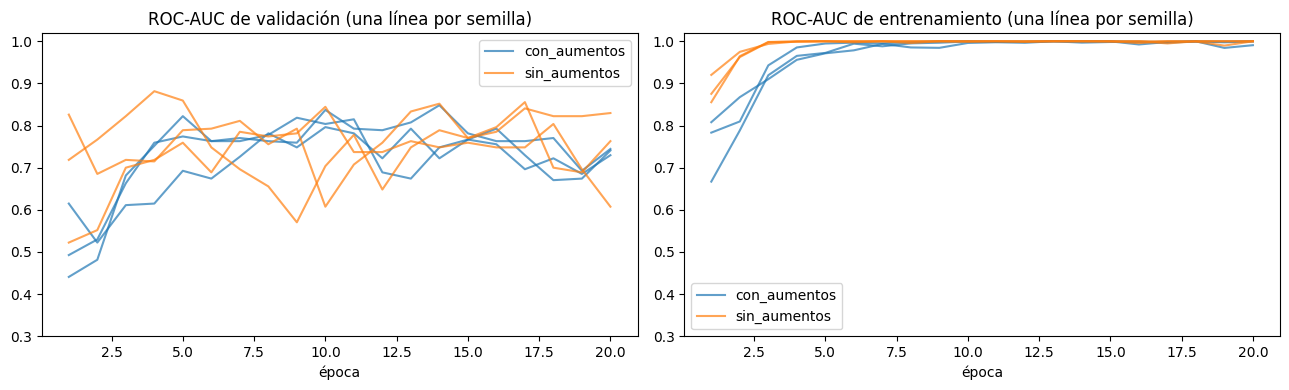

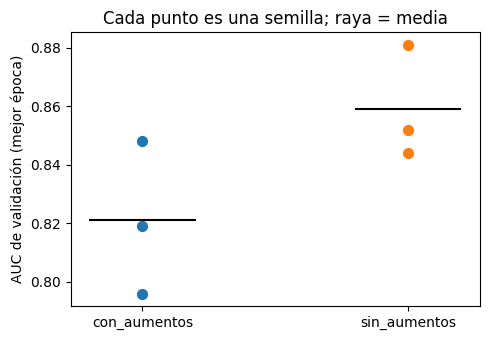

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
colores = {"con_aumentos": "tab:blue", "sin_aumentos": "tab:orange"}
for (cond, sem), h in historiales.items():
    ax[0].plot(h.epoca, h.auc_val, c=colores[cond], alpha=.7,
               label=cond if sem == SEMILLAS[0] else None)
    ax[1].plot(h.epoca, h.auc_train, c=colores[cond], alpha=.7,
               label=cond if sem == SEMILLAS[0] else None)
ax[0].set_title("ROC-AUC de validación (una línea por semilla)")
ax[1].set_title("ROC-AUC de entrenamiento (una línea por semilla)")
for a in ax:
    a.set_xlabel("época"); a.set_ylim(0.3, 1.02); a.legend()
plt.tight_layout()
plt.savefig(f"{RES}/experimento_curvas.png", dpi=110, bbox_inches="tight")
plt.show()

fig, a = plt.subplots(figsize=(5, 3.5))
for i, cond in enumerate(CONDICIONES):
    v = res[res.condicion == cond].auc_val
    a.scatter([i] * len(v), v, c=colores[cond], s=50)
    a.hlines(v.mean(), i - .2, i + .2, colors="k")
a.set_xticks(range(len(CONDICIONES))); a.set_xticklabels(CONDICIONES)
a.set_ylabel("AUC de validación (mejor época)"); a.set_title("Cada punto es una semilla; raya = media")
plt.tight_layout()
plt.savefig(f"{RES}/experimento_auc_por_semilla.png", dpi=110, bbox_inches="tight")
plt.show()

## Decisión según la regla fijada antes de ejecutar

In [6]:
dif = resumen.loc["sin_aumentos", "auc_val_media"] - resumen.loc["con_aumentos", "auc_val_media"]
elegida = "sin_aumentos" if dif >= MARGEN else "con_aumentos"
print(f"AUC medio sin - con aumentos: {dif:+.3f} (margen exigido: +{MARGEN})")
print("Condición elegida:", elegida)

fila = res[(res.condicion == elegida) & (res.semilla == 42)].iloc[0]
final = dict(modelo="resnet18", condicion=elegida, **CONDICIONES[elegida], semilla=42,
             ckpt=f"exp_{elegida}_s42.pt", mejor_epoca=int(fila.mejor_epoca),
             auc_val=float(fila.auc_val), auc_val_ic95=fila.auc_val_ic95,
             fecha=datetime.datetime.now().strftime("%Y-%m-%d %H:%M"))
json.dump(final, open(f"{RES}/modelo_final.json", "w"), indent=1, ensure_ascii=False)
pd.read_csv(f"{EXP}/pred_val_{elegida}_s42.csv").to_csv(f"{RES}/pred_val_final.csv", index=False)
print(json.dumps(final, indent=1, ensure_ascii=False))

AUC medio sin - con aumentos: +0.038 (margen exigido: +0.02)
Condición elegida: sin_aumentos
{
 "modelo": "resnet18",
 "condicion": "sin_aumentos",
 "flip": false,
 "rotacion": 0,
 "semilla": 42,
 "ckpt": "exp_sin_aumentos_s42.pt",
 "mejor_epoca": 4,
 "auc_val": 0.881,
 "auc_val_ic95": "0.72-1.00",
 "fecha": "2026-11-21 22:11"
}


## Cómo leer el resultado (sin sobreinterpretar)
- Compara la **diferencia entre condiciones** con la **variación entre semillas** de una misma
  condición. Si los puntos de las dos condiciones se mezclan, la diferencia no se distingue del
  azar del entrenamiento.
- La **brecha train-val** indica sobreajuste: si sin aumentos la brecha es mayor, los aumentos
  frenan algo la memorización.
- Son 37 lesiones de validación (10 malignas): una diferencia pequeña de AUC puede ser ruido.
- La comprobación de reproducibilidad debería dar una diferencia cercana a 0. Si no, anota en la
  bitácora que en GPU los resultados no son exactamente repetibles.